# EDA piloto de temperatura a 2 m con NASA POWER

**Pregunta exploratoria:** ¿Cómo ha variado la temperatura del aire a 2 metros en un punto de la región candidata durante el período histórico seleccionado?

Este laboratorio analiza la serie **puntual** de Wagga Wagga, Nueva Gales del Sur, Australia. El lugar está en el corredor del río Murrumbidgee, tributario principal del sistema Murray; el punto sirve como caso piloto dentro de la región candidata Murray–Darling, pero no representa un promedio de la cuenca.

Se solicita frecuencia mensual entre enero de 2005 y diciembre de 2024. NASA POWER es la fuente utilizada para probar el proceso de exploración; su temperatura meteorológica se basa en MERRA-2. El producto se consulta por su API mensual y los datos originales se conservan localmente.

El propósito es explorar cobertura, calidad, distribución, ciclo estacional y dependencia temporal. No se contrasta una hipótesis causal ni se declara una tendencia regional definitiva.

## A. Fuente, procedencia y localización

- **Institución/servicio:** NASA Langley Research Center, Prediction Of Worldwide Energy Resources (POWER), Monthly and Annual API.
- **Parámetro:** T2M, Temperature at 2 Meters.
- **Comunidad solicitada:** AG (Agroclimatology); el JSON de respuesta documenta la fuente meteorológica MERRA2.
- **Unidad:** se lee desde los metadatos devueltos por NASA; la respuesta informa C (grados Celsius). En las etiquetas de los gráficos se muestra °C.
- **Frecuencia y tiempo:** mensual; la respuesta informa su convención temporal.
- **Lugar:** Wagga Wagga, New South Wales, Australia.
- **Coordenadas solicitadas:** las coordenadas del lugar en el listado de lugares reconocidos del Australian Government Bureau of Meteorology: latitud -35.1257741166667, longitud 147.353737883333. Consultado el 14 de noviembre de 2026.
- **Justificación:** Wagga Wagga está a orillas del Murrumbidgee; el gobierno de NSW describe ese río como tributario del sistema Murray. El punto es reproducible y se encuentra en la región candidata, pero solo mide el punto de grilla de POWER asociado.
- **URL del servicio:** https://power.larc.nasa.gov/api/temporal/monthly/point
- **Documentación:** [NASA POWER Monthly API](https://power.larc.nasa.gov/docs/services/api/temporal/monthly/), [coordenadas BOM](https://www.bom.gov.au/water/groundwater/gde/service/simple-location-list.php?letter=W), [Murrumbidgee y sistema Murray, Wagga Wagga City Council](https://www.wagga.nsw.gov.au/__data/assets/pdf_file/0018/4356/200905_Wagga_Wagga_-_Floodplain_Risk_Management_Study_-_Final.pdf).

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "pyproject.toml").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("No se encontró la raíz del proyecto (pyproject.toml).")
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

from research.power_data import (
    LOCATION,
    build_power_query,
    fetch_power_response,
    parse_power_annual,
    parse_power_monthly,
)
from research.series_quality import (
    descriptive_summary,
    monthly_climatology_and_anomalies,
    quality_summary,
)

START_YEAR, END_YEAR = 2005, 2024
RAW_PATH = PROJECT_ROOT / "data/raw/nasa_power_t2m_wagga-wagga_2005-2024.json"
query = build_power_query(START_YEAR, END_YEAR)
payload, provenance = fetch_power_response(RAW_PATH, query=query)
series = parse_power_monthly(payload, latitude=LOCATION["latitude"], longitude=LOCATION["longitude"])
annual_power = parse_power_annual(payload)

print("NASA POWER URL:", provenance["request_url"])
print("Fecha de consulta (UTC):", provenance.get("retrieved_at_utc", "desconocida: archivo local previo"))
print("Archivo original:", RAW_PATH.relative_to(PROJECT_ROOT))
print("Tamaño original (bytes):", RAW_PATH.stat().st_size)
print("Hash SHA-256 del JSON original:", hashlib.sha256(RAW_PATH.read_bytes()).hexdigest())

NASA POWER URL: https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M&community=AG&longitude=147.353737883333&latitude=-35.1257741166667&start=2005&end=2024&format=JSON
Fecha de consulta (UTC): 2026-11-14T16:00:03.569878+00:00
Archivo original: data\raw\nasa_power_t2m_wagga-wagga_2005-2024.json
Tamaño original (bytes): 7426
Hash SHA-256 del JSON original: 82c88d208217fc02e0bf7798725fd2392888c260447c88227b8df2efdd66f8b3


## B. Respuesta y metadatos

La respuesta original está guardada sin transformar en data/raw/, junto a un sidecar que registra la URL, parámetros, hora de consulta, metadatos del parámetro, encabezado y geometría reportada por POWER. Se mantienen separados el punto solicitado y la geometría que devuelve el servicio, que representa la ubicación de grilla asociada.

El endpoint mensual devuelve valores agrupados por año. En esta respuesta la clave de mes 13 es el resumen anual incluido por POWER; el parser mensual la excluye de la serie mensual. Se extrae por separado para conservar la distinción entre observación mensual y resumen anual, sin borrar ni alterar el JSON original.

In [2]:
parameter_meta = payload["parameters"]["T2M"]
display_unit = {"C": "°C"}.get(parameter_meta.get("units"), parameter_meta.get("units", "unidad no informada"))
header = payload.get("header", {})
geometry = payload.get("geometry", {})
metadata_table = pd.DataFrame(
    [
        ("Institución", provenance["institution"]),
        ("Servicio", provenance["service"]),
        ("API / versión", f'{header.get("api", {}).get("name")} / {header.get("api", {}).get("version")}'),
        ("URL consultada", provenance["request_url"]),
        ("Parámetros", json.dumps(provenance["parameters"], ensure_ascii=False)),
        ("Variable", "T2M — " + parameter_meta.get("longname", "sin descripción")),
        ("Unidad devuelta por NASA", parameter_meta.get("units", "no informada")),
        ("Lugar", f'{LOCATION["name"]}, {LOCATION["region"]}, {LOCATION["country"]}'),
        ("Coordenadas solicitadas (lat, lon)", f'{LOCATION["latitude"]}, {LOCATION["longitude"]}'),
        ("Geometría POWER reportada (lon, lat, elevación)", str(geometry.get("coordinates"))),
        ("Fuente meteorológica informada", ", ".join(header.get("sources", []))),
        ("Convención temporal", header.get("time_standard")),
        ("Fill value del servicio", header.get("fill_value")),
        ("Período solicitado", f'{START_YEAR}–{END_YEAR}'),
        ("Período informado por la respuesta", f'{header.get("start")}–{header.get("end")}'),
        ("Fecha de consulta UTC", provenance.get("retrieved_at_utc")),
        ("Registros incluyendo resúmenes anuales", provenance.get("received_record_count_including_annual_summaries")),
        ("Registros mensuales / anuales parseados por separado", f"{len(series)} / {len(annual_power)}"),
    ],
    columns=["Campo", "Valor"],
)
display(metadata_table)
print("Mensajes del servicio:", payload.get("messages", []))

,Campo,Valor
0,Institución,NASA Langley Research Center POWER Project
1,Servicio,NASA POWER Monthly and Annual API
2,API / versión,POWER Monthly and Annual API / v2.10.0
3,URL consultada,https://power.larc.nasa.gov/api/temporal/month...
4,Parámetros,"{""parameters"": ""T2M"", ""community"": ""AG"", ""long..."
5,Variable,T2M — Temperature at 2 Meters
6,Unidad devuelta por NASA,C
7,Lugar,"Wagga Wagga, New South Wales, Australia"
8,"Coordenadas solicitadas (lat, lon)","-35.1257741166667, 147.353737883333"
9,"Geometría POWER reportada (lon, lat, elevación)","[147.354, -35.126, 285.71]"


Mensajes del servicio: []


## C. Carga y estructura de la serie mensual

El DataFrame contiene un renglón por clave mensual válida y metadatos mínimos para que las funciones posteriores no pierdan fuente, unidad ni ubicación. Los resúmenes anuales del mes 13 no forman parte de esta serie.

In [3]:
print("Columnas:", series.columns.tolist())
print("\nTipos:")
display(series.dtypes.rename("dtype").to_frame())
print("\nPrimeras observaciones:")
display(series.head())
print("\nÚltimas observaciones:")
display(series.tail())
print("\nRegistros mensuales recibidos:", len(series))
print("Período recibido:", series["timestamp"].min(), "a", series["timestamp"].max())
print("Frecuencia de timestamp: inicio de mes; unidad:", series["unit"].dropna().unique())

Columnas: ['timestamp', 'value', 'variable', 'unit', 'source', 'latitude', 'longitude', 'is_missing']

Tipos:


,dtype
timestamp,datetime64[us]
value,float64
variable,str
unit,str
source,str
latitude,float64
longitude,float64
is_missing,bool



Primeras observaciones:


,timestamp,value,variable,unit,source,latitude,longitude,is_missing
0,2005-01-01,25.21,T2M,C,NASA POWER,-35.125774,147.353738,False
1,2005-02-01,21.71,T2M,C,NASA POWER,-35.125774,147.353738,False
2,2005-03-01,19.80,T2M,C,NASA POWER,-35.125774,147.353738,False
3,2005-04-01,19.14,T2M,C,NASA POWER,-35.125774,147.353738,False
4,2005-05-01,12.79,T2M,C,NASA POWER,-35.125774,147.353738,False



Últimas observaciones:


,timestamp,value,variable,unit,source,latitude,longitude,is_missing
235,2024-08-01,11.27,T2M,C,NASA POWER,-35.125774,147.353738,False
236,2024-09-01,12.47,T2M,C,NASA POWER,-35.125774,147.353738,False
237,2024-10-01,17.03,T2M,C,NASA POWER,-35.125774,147.353738,False
238,2024-11-01,22.17,T2M,C,NASA POWER,-35.125774,147.353738,False
239,2024-12-01,24.16,T2M,C,NASA POWER,-35.125774,147.353738,False



Registros mensuales recibidos: 240
Período recibido: 2005-01-01 00:00:00 a 2024-12-01 00:00:00
Frecuencia de timestamp: inicio de mes; unidad: <StringArray>
['C']
Length: 1, dtype: str


## D. Validación de calidad y cobertura

Se compara la cobertura con los 240 meses calendario solicitados. Fill values declarados por el propio encabezado de POWER se convierten en ausencias; los nulos y no finitos también se marcan. No se imputan valores. Una fecha ausente se distingue de un mes recibido cuyo valor está ausente. Se detectan duplicados incluso si el parser normal normalmente evita producirlos.

Los duplicados exactos se calculan por timestamp; los duplicados mensuales agrupan timestamps distintos que caen en el mismo período YYYY-MM. Las métricas *_rows cuentan todas las filas participantes, mientras *_repeats cuenta repeticiones posteriores a la primera y *_count cuenta períodos distintos con duplicados. Los timestamp ausentes no se consideran un período duplicado.

In [4]:
quality = quality_summary(series, f"{START_YEAR}-01", f"{END_YEAR}-12")
quality_table = pd.DataFrame(
    {"Métrica": list(quality), "Resultado": [str(value) for value in quality.values()]}
)
display(quality_table)
print("Meses ausentes del calendario solicitado:", quality["absent_months"])
print("Registros con is_missing=True:", int(series["is_missing"].sum()))
print("Valores numéricos no finitos:", quality["non_finite_values"])
print("Filas en duplicados de timestamp exacto:", quality["duplicate_timestamp_rows"])
print("Repeticiones exactas posteriores a la primera (métrica heredada duplicate_months):", quality["duplicate_months"])
print("Filas en meses con varios registros:", quality["duplicate_month_rows"])
print("Períodos mensuales distintos duplicados:", quality["duplicate_months_count"])

,Métrica,Resultado
0,expected_months,240
1,received_rows,240
2,valid_months,240
3,missing_or_invalid_rows,0
4,missing_or_invalid_percent_of_expected,0.0
5,duplicate_rows,0
6,duplicate_months,0
7,duplicate_timestamp_rows,0
8,duplicate_timestamp_repeats,0
9,duplicate_month_rows,0


Meses ausentes del calendario solicitado: []
Registros con is_missing=True: 0
Valores numéricos no finitos: 0
Filas en duplicados de timestamp exacto: 0
Repeticiones exactas posteriores a la primera (métrica heredada duplicate_months): 0
Filas en meses con varios registros: 0
Períodos mensuales distintos duplicados: 0


## E. Estadística descriptiva

Los estadísticos se calculan únicamente sobre valores finitos no marcados como faltantes y conservan la unidad devuelta por POWER. Los promedios anuales se presentan solo si el año tiene los doce meses válidos, para evitar comparar años parciales como si fueran equivalentes.

In [5]:
stats = descriptive_summary(series)
display(stats.rename("Temperatura").to_frame())
monthly_valid = series.loc[~series["is_missing"]].copy()
monthly_valid["year"] = monthly_valid["timestamp"].dt.year
monthly_valid["calendar_month"] = monthly_valid["timestamp"].dt.month
monthly_yearly = monthly_valid.groupby("year").agg(
    monthly_value_count=("value", "count"),
    monthly_equal_weight_mean=("value", "mean"),
)
annual = annual_power.rename(columns={"value": "api_annual_value"}).set_index("year")
annual = annual.join(monthly_yearly)
annual["monthly_equal_weight_mean"] = annual["monthly_equal_weight_mean"].where(
    annual["monthly_value_count"].eq(12)
)
display(annual)
calendar_month_summary = monthly_valid.groupby("calendar_month")["value"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
display(calendar_month_summary)

,Temperatura
count,240.000000
mean,16.050083
std,6.449436
min,6.190000
25%,9.867500
50%,15.605000
75%,21.715000
max,29.800000
iqr,11.847500


,api_annual_value,unit,variable,is_missing,monthly_value_count,monthly_equal_weight_mean
year,,,,,,
2005,16.06,C,T2M,False,12,16.091667
2006,16.66,C,T2M,False,12,16.701667
2007,16.63,C,T2M,False,12,16.689167
2008,15.60,C,T2M,False,12,15.611667
2009,16.72,C,T2M,False,12,16.771667
2010,15.21,C,T2M,False,12,15.255833
2011,15.20,C,T2M,False,12,15.237500
2012,14.97,C,T2M,False,12,14.995833
2013,16.34,C,T2M,False,12,16.383333


,count,mean,median,std,min,max
calendar_month,,,,,,
1,20,25.7140,25.735,1.516809,23.66,29.80
2,20,24.0150,24.530,1.558955,21.40,26.49
3,20,20.9550,21.260,1.550564,17.22,23.11
4,20,15.9775,15.585,1.586094,13.82,19.41
5,20,11.2780,11.380,1.089397,9.43,13.30
6,20,8.2050,7.975,0.773356,7.11,10.02
7,20,7.3545,7.250,0.585271,6.19,8.34
8,20,8.5325,8.335,1.158033,6.93,11.27
9,20,11.8175,11.660,0.978785,10.34,14.51


## F. Visualizaciones descriptivas

La media móvil de 12 meses se muestra como suavizado descriptivo; no es una prueba de tendencia. Las anomalías se definen respecto de la media de cada mes calendario durante 2005–2024, el período completo solicitado. Están expresadas en la unidad original y no son anomalías estadísticamente significativas.

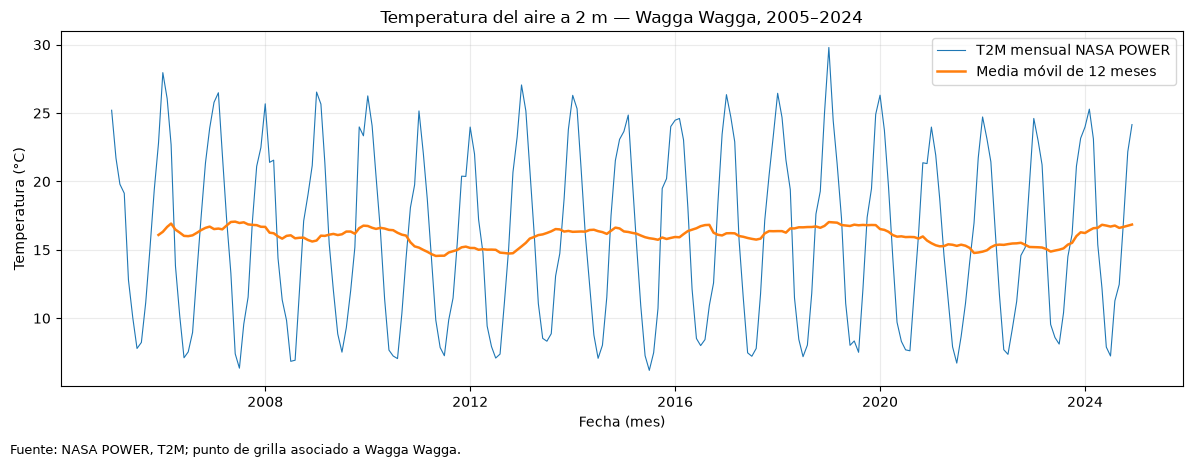

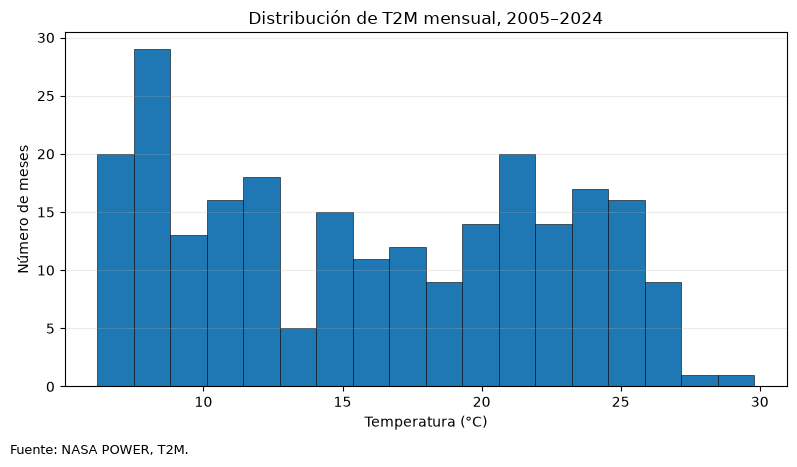

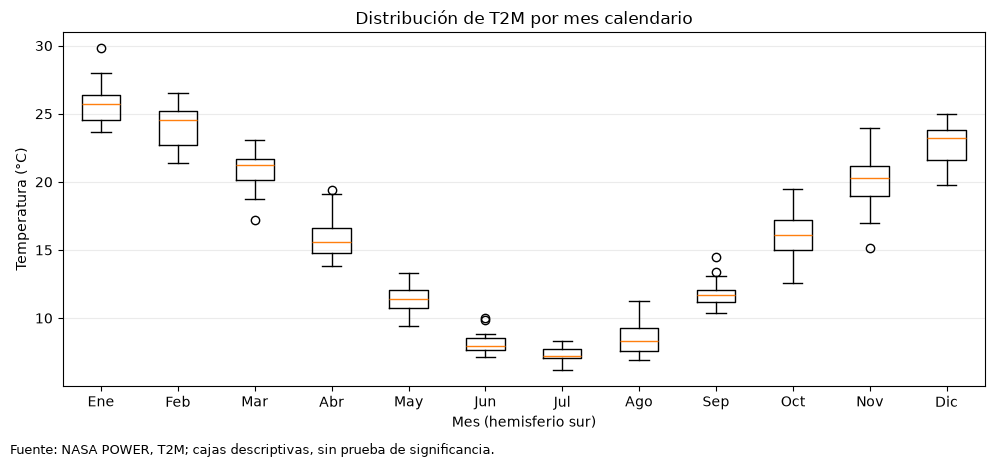

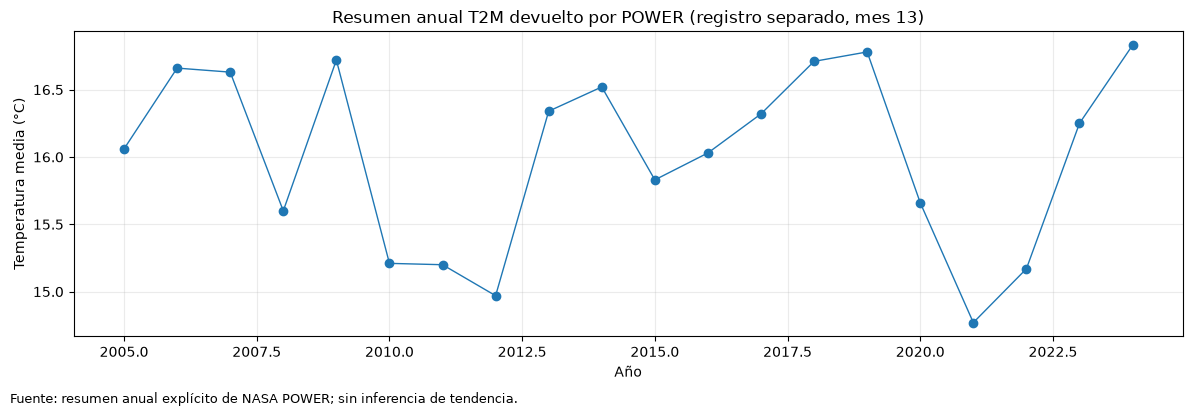

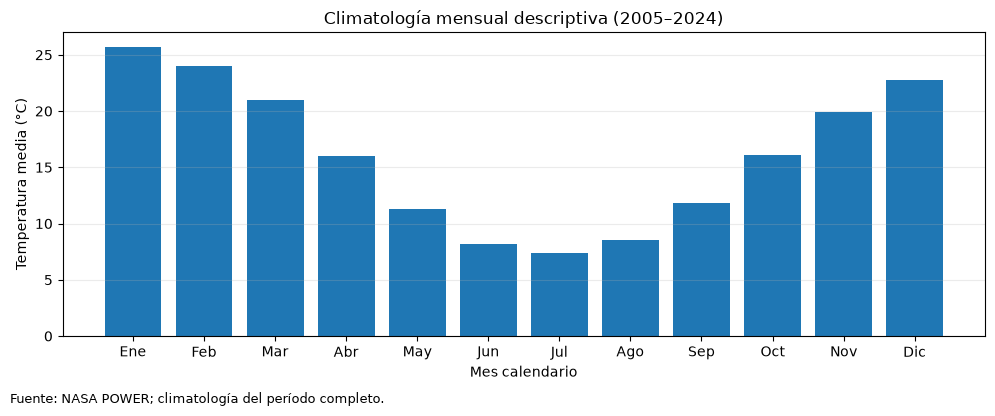

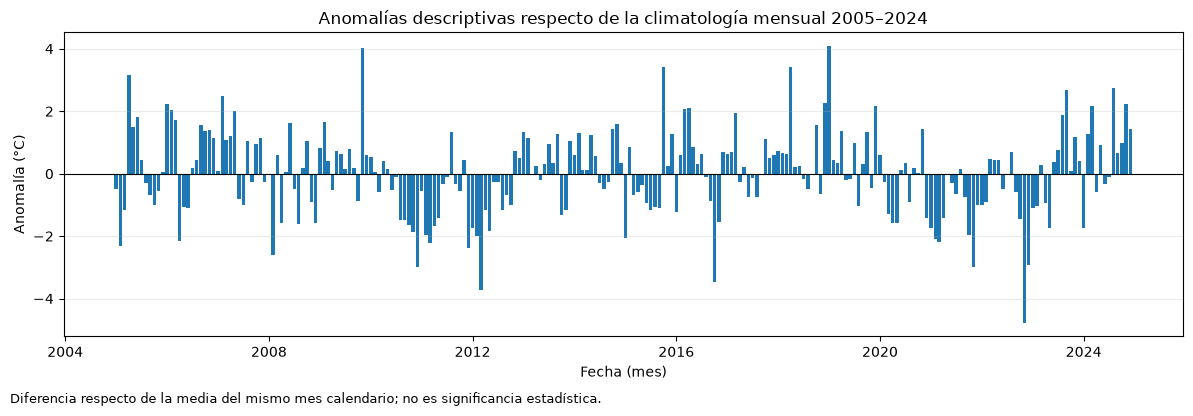

In [6]:
climatology, anomalies = monthly_climatology_and_anomalies(
    series, reference_start=f"{START_YEAR}-01", reference_end=f"{END_YEAR}-12"
)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(series["timestamp"], series["value"], linewidth=0.8, label="T2M mensual NASA POWER")
ax.plot(series["timestamp"], series["value"].rolling(12, min_periods=12).mean(),
        linewidth=1.8, label="Media móvil de 12 meses")
ax.set(title="Temperatura del aire a 2 m — Wagga Wagga, 2005–2024",
       xlabel="Fecha (mes)", ylabel=f'Temperatura ({display_unit})')
ax.legend()
ax.grid(alpha=0.25)
fig.text(0.01, -0.02, "Fuente: NASA POWER, T2M; punto de grilla asociado a Wagga Wagga.", fontsize=9)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(monthly_valid["value"], bins=18, edgecolor="black", linewidth=0.4)
ax.set(title="Distribución de T2M mensual, 2005–2024",
       xlabel=f'Temperatura ({display_unit})', ylabel="Número de meses")
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, -0.02, "Fuente: NASA POWER, T2M.", fontsize=9)
fig.tight_layout()
plt.show()

month_labels = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
box_data = [monthly_valid.loc[monthly_valid["calendar_month"].eq(month), "value"] for month in range(1, 13)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(box_data, tick_labels=month_labels, showfliers=True)
ax.set(title="Distribución de T2M por mes calendario",
       xlabel="Mes (hemisferio sur)", ylabel=f'Temperatura ({display_unit})')
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, -0.02, "Fuente: NASA POWER, T2M; cajas descriptivas, sin prueba de significancia.", fontsize=9)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(annual.index, annual["api_annual_value"], marker="o", linewidth=1)
ax.set(title="Resumen anual T2M devuelto por POWER (registro separado, mes 13)",
       xlabel="Año", ylabel=f'Temperatura media ({display_unit})')
ax.grid(alpha=0.25)
fig.text(0.01, -0.02, "Fuente: resumen anual explícito de NASA POWER; sin inferencia de tendencia.", fontsize=9)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(climatology.index, climatology.values)
ax.set_xticks(range(1, 13), month_labels)
ax.set(title=f"Climatología mensual descriptiva ({START_YEAR}–{END_YEAR})",
       xlabel="Mes calendario", ylabel=f'Temperatura media ({display_unit})')
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, -0.02, "Fuente: NASA POWER; climatología del período completo.", fontsize=9)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.bar(anomalies.index, anomalies.values, width=25)
ax.set(title=f"Anomalías descriptivas respecto de la climatología mensual {START_YEAR}–{END_YEAR}",
       xlabel="Fecha (mes)", ylabel=f'Anomalía ({display_unit})')
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, -0.02, "Diferencia respecto de la media del mismo mes calendario; no es significancia estadística.", fontsize=9)
fig.tight_layout()
plt.show()

## G. Estacionalidad

Wagga Wagga está en el hemisferio sur: verano = diciembre–febrero, otoño = marzo–mayo, invierno = junio–agosto y primavera = septiembre–noviembre. La tabla y las gráficas son comparaciones descriptivas, sin tratar las diferencias observadas como pruebas de significancia. La anomalía mensual elimina el patrón medio del mes calendario definido sobre el período de referencia.

In [7]:
season_by_month = {
    12: "Verano", 1: "Verano", 2: "Verano",
    3: "Otoño", 4: "Otoño", 5: "Otoño",
    6: "Invierno", 7: "Invierno", 8: "Invierno",
    9: "Primavera", 10: "Primavera", 11: "Primavera",
}
monthly_valid["season"] = monthly_valid["calendar_month"].map(season_by_month)
season_order = ["Verano", "Otoño", "Invierno", "Primavera"]
season_summary = monthly_valid.groupby("season")["value"].agg(["count", "mean", "std", "min", "max"]).reindex(season_order)
display(season_summary)
warmest_month = int(calendar_month_summary["mean"].idxmax())
coolest_month = int(calendar_month_summary["mean"].idxmin())
print(f"Mayor media calendario: {month_labels[warmest_month - 1]} ({calendar_month_summary.loc[warmest_month, 'mean']:.2f} {parameter_meta['units']}).")
print(f"Menor media calendario: {month_labels[coolest_month - 1]} ({calendar_month_summary.loc[coolest_month, 'mean']:.2f} {parameter_meta['units']}).")
print("La variabilidad interanual se resume por medias anuales solo cuando hay 12 meses válidos:")
display(annual[["monthly_value_count", "api_annual_value", "monthly_equal_weight_mean"]].describe())

,count,mean,std,min,max
season,,,,,
Verano,60,24.157500,1.953161,19.76,29.80
Otoño,60,16.070167,4.224081,9.43,23.11
Invierno,60,8.030667,0.992687,6.19,11.27
Primavera,60,15.942000,3.687161,10.34,23.99


Mayor media calendario: Ene (25.71 C).
Menor media calendario: Jul (7.35 C).
La variabilidad interanual se resume por medias anuales solo cuando hay 12 meses válidos:


,monthly_value_count,api_annual_value,monthly_equal_weight_mean
count,20.0,20.000000,20.000000
mean,12.0,16.013000,16.050083
std,0.0,0.670256,0.673188
min,12.0,14.770000,14.808333
25%,12.0,15.502500,15.522708
50%,12.0,16.155000,16.188333
75%,12.0,16.637500,16.692292
max,12.0,16.830000,16.850833


## H. Autocorrelación preliminar

La función de autocorrelación (ACF) se inspecciona en la serie observada y en las anomalías mensuales descriptivas. El patrón de la serie original mezcla persistencia temporal y ciclo estacional; la ACF de anomalías ayuda a inspeccionar la persistencia remanente una vez retirada la media de cada mes calendario. Los intervalos usuales del gráfico son aproximaciones descriptivas basadas en supuestos simplificadores; no son un diagnóstico completo ni una prueba de tendencia.

ACF original: rezago 1 = 0.834; rezago 12 = 0.915.
ACF anomalías: rezago 1 = 0.403; rezago 12 = 0.022.


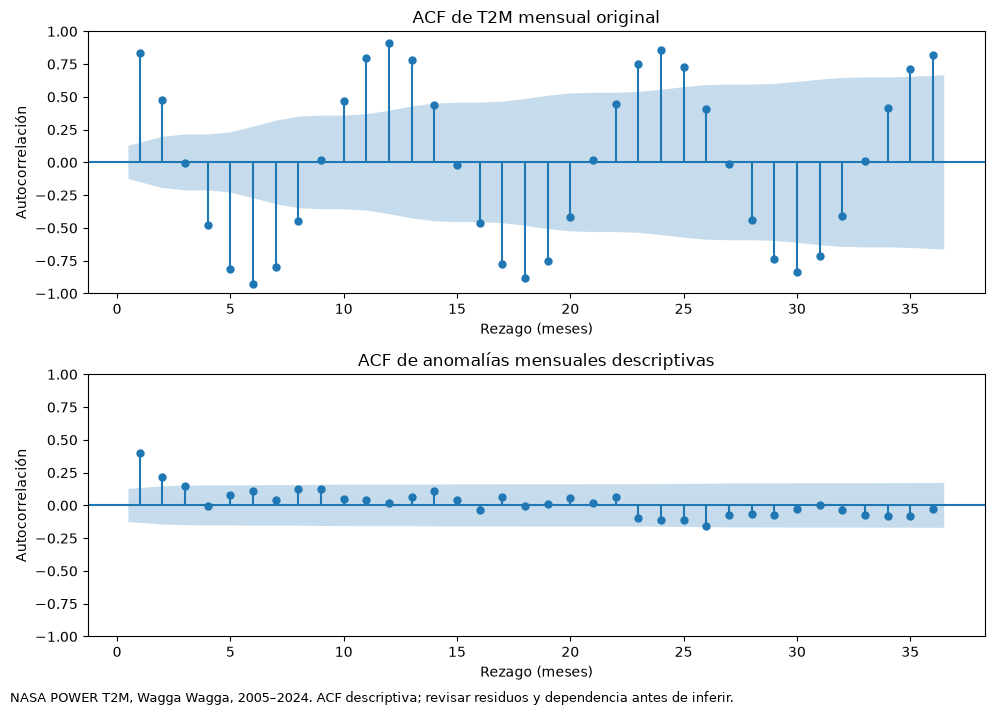

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
plot_acf(monthly_valid["value"], lags=36, zero=False, ax=axes[0], missing="drop")
original_acf = acf(monthly_valid["value"], nlags=24, fft=False, missing="drop")
axes[0].set_title("ACF de T2M mensual original")
anomaly_series = anomalies.sort_index()
plot_acf(anomaly_series, lags=36, zero=False, ax=axes[1], missing="drop")
anomaly_acf = acf(anomaly_series, nlags=24, fft=False, missing="drop")
print(f"ACF original: rezago 1 = {original_acf[1]:.3f}; rezago 12 = {original_acf[12]:.3f}.")
print(f"ACF anomalías: rezago 1 = {anomaly_acf[1]:.3f}; rezago 12 = {anomaly_acf[12]:.3f}.")
axes[1].set_title("ACF de anomalías mensuales descriptivas")
for ax in axes:
    ax.set_xlabel("Rezago (meses)")
    ax.set_ylabel("Autocorrelación")
fig.text(0.01, -0.01, "NASA POWER T2M, Wagga Wagga, 2005–2024. ACF descriptiva; revisar residuos y dependencia antes de inferir.", fontsize=9)
fig.tight_layout()
plt.show()

## I. Hallazgos exploratorios calculados

Los siguientes valores se generan desde la respuesta NASA guardada en este entorno. Se describen cobertura, rango y ciclo calendario observados; no se calculan p-values, intervalos de tendencia ni causalidad.

In [9]:
valid_values = monthly_valid["value"]
print(f"Cobertura: {quality['valid_months']} observaciones válidas de {quality['expected_months']} meses esperados "
      f"({100 - quality['missing_or_invalid_percent_of_expected']:.1f}% de cobertura).")
print(f"Rango observado: {valid_values.min():.2f} a {valid_values.max():.2f} {parameter_meta['units']}.")
print(f"Media y mediana: {valid_values.mean():.2f} y {valid_values.median():.2f} {parameter_meta['units']}.")
print(f"Ciclo estacional descriptivo: mayor media en {month_labels[warmest_month - 1]} y menor en {month_labels[coolest_month - 1]}.")
print(f"Duplicados exactos: {quality['duplicate_timestamp_rows']} filas; duplicados mensuales: {quality['duplicate_month_rows']} filas en {quality['duplicate_months_count']} períodos; meses ausentes: {len(quality['absent_months'])}; valores faltantes/inválidos: {quality['missing_or_invalid_rows']}.")
print("Interpretación: un punto de grilla y una serie de reanálisis mensual no bastan para inferir cambios de toda la cuenca.")

Cobertura: 240 observaciones válidas de 240 meses esperados (100.0% de cobertura).
Rango observado: 6.19 a 29.80 C.
Media y mediana: 16.05 y 15.61 C.
Ciclo estacional descriptivo: mayor media en Ene y menor en Jul.
Duplicados exactos: 0 filas; duplicados mensuales: 0 filas en 0 períodos; meses ausentes: 0; valores faltantes/inválidos: 0.
Interpretación: un punto de grilla y una serie de reanálisis mensual no bastan para inferir cambios de toda la cuenca.


## J. Métodos candidatos para un trabajo posterior

No se selecciona método ni se ejecuta un contraste definitivo para Murray–Darling. La significancia estadística evalúa compatibilidad con una hipótesis bajo supuestos del modelo; el tamaño del efecto describe magnitud y unidad; la incertidumbre expresa precisión; una anomalía es una diferencia frente a una referencia; la importancia ambiental requiere contexto externo y no se deduce de un p-value.

| Método | Propósito | Supuestos | Ventajas | Limitaciones | Diagnósticos necesarios |
|---|---|---|---|---|---|
| Regresión lineal OLS | Estimar cambio medio por unidad de tiempo; expresar la pendiente, por ejemplo en °C/década | Relación media lineal; residuos con media cero; inferencia clásica requiere independencia, varianza constante y distribución adecuada para muestras pequeñas | Efecto y forma de tendencia interpretables; permite covariables justificadas | Estacionalidad omitida sesga/residuales; autocorrelación hace que errores estándar OLS y p-values sean demasiado optimistas; extremos pueden influir | Gráfico temporal y residuos, forma funcional, estacionalidad, heterocedasticidad, ACF/PACF de residuos, puntos influyentes y sensibilidad al período |
| OLS con errores estándar HAC / Newey–West | Corregir la estimación de incertidumbre de coeficientes OLS ante heterocedasticidad y autocorrelación de corto alcance | Serie temporal igualmente espaciada; especificación de media razonable; elección de rezago/kernel; dependencia suficientemente débil para la aproximación | Mantiene la pendiente OLS y ajusta su matriz de covarianza | No cambia la pendiente ni arregla forma funcional, tendencia no lineal, estacionalidad omitida, quiebres, confusión o autocorrelación de largo alcance; elección de rezago importa | Todo diagnóstico OLS más sensibilidad a rezago HAC, kernel y especificación |
| Pendiente Theil–Sen | Estimar pendiente como mediana de pendientes entre pares | Tendencia aproximadamente monotónica/lineal para interpretación única; errores y muestreo deben permitir inferencia válida | Resiste mejor a valores extremos que OLS; estimador simple de pendiente | No elimina ciclo estacional ni dependencia; intervalo estándar no corrige autocorrelación; millones de pares pueden costar en series largas | Estacionalidad, huecos, dependencia, sensibilidad a extremos/período; unidades y escala temporal explícitas |
| Mann–Kendall estacional / Seasonal Kendall | Evaluar tendencia monótona comparando rangos dentro de cada estación (p. ej., cada mes calendario) | Observaciones comparables dentro de estación; tendencia monótona; tratamiento de empates/faltantes y dependencia adecuado | No exige normalidad y conserva la estructura estacional; puede tolerar valores faltantes | Autocorrelación puede distorsionar tamaño del test, sobre todo persistencia fuerte; no da tamaño de cambio por sí solo; cambios no monótonos pueden pasar inadvertidos | ACF y persistencia, cobertura por mes, empates, quiebres, homogeneidad, corrección de dependencia y estimación separada de tamaño del efecto |

Para una tendencia lineal, pendiente × 10 expresa cambio por década si el eje temporal está en años. Una pendiente no es causalidad. En series mensuales, cualquier contraste debe modelar o estratificar el ciclo anual, revisar autocorrelación residual, valores extremos, completitud y homogeneidad. HAC cambia incertidumbre, no repara un modelo mal especificado. La versión estacional de Mann–Kendall fue diseñada para datos estacionales; la literatura también estudia el efecto de dependencia serial.

Referencias:
- [NASA POWER Monthly API y formatos/parámetros](https://power.larc.nasa.gov/docs/services/api/temporal/monthly/)
- [SciPy: theilslopes](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.theilslopes.html)
- [statsmodels: cov_hac (Newey–West)](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html)
- [Hirsch, Slack & Smith (1982), técnicas de tendencia para datos mensuales](https://doi.org/10.1029/WR018i001p00107)
- [Hirsch & Slack (1984), Seasonal Kendall con dependencia serial](https://doi.org/10.1029/WR020i006p00727)

## K. Checklist para muestras oficiales MERRA-2, IMERG y GLDAS

**Aplicar cuando Alaín entregue archivos; aquí no se abre ni transforma ningún granule del MVP.**

- [ ] **Procedencia:** institución, producto, shortname, versión, granule, fecha de descarga, DOI/URL, checksum y transformaciones.
- [ ] **Estructura:** formato científico, dimensiones, nombres y unidades de coordenadas, variable, dimensión temporal, calendario, resolución espacial y CRS.
- [ ] **Calidad:** fill values/missing_value, flags QA, escala/offset, unidades físicas, rango válido documentado, cobertura espacial/temporal, meses incompletos y cambios de versión/sensor.
- [ ] **Procesamiento:** preservar archivo original; definir recorte, máscara del polígono de cuenca, conversión de unidades, pesos por área de celda y reglas de agregación mensual; registrar cada paso.
- [ ] **Estadística:** longitud y cobertura mensual por estación, ciclo estacional, autocorrelación, homogeneidad/quiebres, extremos, método y corrección de dependencia, intervalos de confianza y sensibilidad al período.
- [ ] **Comparabilidad:** confirmar alineación espacial/temporal y definición del estimando antes de comparar productos; documentar que sus resoluciones y fuentes difieren.

## L. Propuesta de formato interno para integrar análisis con Alaín

Propuesta de fila larga para la **entrada interna** del análisis, no contrato de endpoint. Los campos mínimos deben conservar observación, procedencia, soporte espacial y calidad para que el análisis sepa qué representa cada número.

| Campo | Requerido | Significado |
|---|---:|---|
| variable_id | Sí | Identificador estable (p. ej., T2M, precipitation, SoilMoi0_10cm_inst) |
| timestamp | Sí | Período representado, preferentemente ISO 8601 o inicio del mes más frecuencia explícita |
| value | Sí, admite null | Valor en unidad original |
| unit | Sí | Unidad física y convención |
| source | Sí | NASA POWER, MERRA-2, IMERG, GLDAS u otra fuente |
| product_id | Sí para NASA | Shortname del producto |
| product_version | Sí cuando aplica | Versión/procesamiento del producto |
| spatial_support_type | Sí | point, grid_cell o polygon_aggregate |
| region_id | Sí | Identificador estable de región o punto |
| quality_status | Sí | válido, faltante, inválido o sospechoso según reglas documentadas |
| missing_reason | Sí si value es null | Fill value, ausencia temporal, QA, fuera de cobertura, etc. |
| transformations | Sí | Lista versionada de conversiones/agregaciones aplicadas; lista vacía si ninguna |
| latitude / longitude | Condicional | Requeridas para punto/celda; opcionales para agregado poligonal |
| granule_id | Opcional | Archivo/escena de origen |
| spatial_resolution | Opcional | Resolución y unidad de la grilla |
| quality_flags | Opcional | Flags fuente sin perder valores originales |
| retrieved_at | Sí para trazabilidad | Instante de adquisición del archivo/fuente |
| checksum | Opcional recomendado | Integridad del archivo crudo |

Un agregado poligonal debe además documentar su máscara, pesos por área, cobertura válida y denominador usado; una celda/punto debe identificar coordenadas solicitadas y coordenadas o celda efectivamente muestreadas. Alaín y Lucas deben revisar nombres, códigos de calidad y si timestamp representa inicio, fin o promedio del intervalo. No define endpoints.

## M. Alcance y limitaciones

- Se estudia un **punto**, no el promedio espacial de la cuenca.
- NASA POWER no reemplaza MERRA-2, GPM IMERG ni GLDAS del MVP; en particular, esta serie es un producto mensual de POWER cuya respuesta identifica MERRA2 como fuente meteorológica.
- Las características de calidad y representación espacial/temporal de POWER no se trasladan automáticamente a los productos del MVP.
- Una variación observada no establece causalidad.
- Las anomalías aquí son desviaciones descriptivas respecto de la climatología mensual del mismo período; no se llamaron significativas.
- Este piloto sirve para preparar procedimientos y preguntas de QA; no es el análisis definitivo de tendencias del desafío.
- Coordenadas del lugar consultadas en el Bureau of Meteorology el 14 de noviembre de 2026; POWER informa adicionalmente la geometría de grilla asociada en el JSON preservado.